<img src="../logo.png" alt="Vegeta" width="240">

# Kestrel fast — compare designs in a minute

A **standalone** comparator for the early loop: a list of candidate designs — span, chord, gap, section, propeller,
motor, battery, bracing, spar — becomes one row of numbers each, from the cheapest methods that still rank designs
correctly against each other:

| what | method | cost |
|---|---|---|
| mass, CG | the mass table on the candidate's layout; battery, propellers, motors and spar corrected | ms |
| section | **Zephyr / NeuralFoil** at the candidate's chord Reynolds number (n_crit 6): $c_{l,max}$ (×0.9 built-up), $c_d$ at the cruise $c_l$, $c_{m0}$, its confidence | ~2 s per section and Re, cached |
| lift slope, neutral point | the vortex lattice on the two wings | 0.1 s |
| drag | the build-up, the section's drag on the wings' share | ms |
| propulsion | **Boreas** blade-element points: the hover, the static full thrust, the cruise, full thrust against speed for $V_{max}$ | ~0.1 s each |
| structure | **rules of thumb**: the spar as a beam under the elliptic lift at 4 g (root moment $M = L_{half}\cdot\tfrac{4}{3\pi}\tfrac{b}{2}$, $\sigma = Mc/I$ at ultimate ×1.5, the tip deflection), the posts as Euler columns under the 75 %-wing share, the wing's first bending mode as a cantilever with the motor at the tip; the plane frame beside it for the standard tube | ms |

**No CFD, no FEA, no transition integration.** Every number is an estimate for ranking — the full study
(`43_kestrel_study`) and the workflows decide. Where they disagree with this page (the CFD's CL max against
NeuralFoil's, for instance) they win. A "very crude FEA" would be neither faster nor more right than the beam formulas
at this stage: the real FEA is the `structure_fea` workflow.

Edit the candidate list, run, read the table and the bars.

In [ ]:
# DEBUG — ON BY DEFAULT: the expensive solvers are mocked (vegeta.mock: fixed numbers, seconds instead of hours,
# labelled MOCK). For real results set DEBUG = False here, or from the shell: VEGETA_DEBUG=0 jupyter nbconvert …
DEBUG = True
from vegeta.labkit import bootstrap
DEBUG = bootstrap.lab("aero", DEBUG)        # the lab's folders on sys.path, the mocks

In [1]:
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import kestrel_fast as kfa
from kestrel_fast import Candidate
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 60); pd.set_option("display.max_colwidth", 60)
t0 = time.time()
print("\n".join(f"{k}: {v}" for k, v in kfa.METHODS.items()))
import yanus                                       # Ozaru's requirement checks: what this notebook needs on this machine
from yanus import AnyOf, Package, Tool
NEEDS = [Package("vegeta.zephyr"),
         Package("vegeta.boreas"),
         AnyOf("section backend", Package("neuralfoil"), Tool("xfoil"), why="Zephyr's 2-D section polars", fix="pip install 'vegeta-cli[sections]' (neuralfoil), or put xfoil on the PATH; ./install_local.sh installs it")]
print(yanus.table(yanus.check_needs(NEEDS)) if NEEDS else "needs: nothing beyond the Python environment")

mass: kestrel_systems.mass_table on the candidate's layout (component data + assumed densities), the battery and propellers scaled
section: Zephyr / NeuralFoil at the candidate's chord Reynolds number, n_crit 6; cl_max × 0.9 for a built-up wing
lift and margin: the vortex lattice on the two wings (kestrel_flight.aero) and the neutral point with the pod and the propellers
drag: kestrel_flight.drag_buildup: skin friction with form factors, the struts, 10 % interference; the section's drag on the wings' share
propulsion: Boreas BEMT (generic blade section, prop_lab's calibration when on file) + the motor's first-order model at a few points
structure: beam theory on the spar (elliptic lift at n g, ultimate × 1.5), Euler buckling of the posts, a cantilever first-mode estimate; the plane frame beside it


## 1. The candidates

`Candidate` fields: `span`, `chord`, `gap` [m], `section` (+ `reflex_k21`), `prop` (`9x6`, `10x6`, `10x7`, `11x7`),
`motor` (`2216 880KV`, `2814 1000KV`), `battery_ah`, `cells`, `bracing` (`x` / `posts` / `none`), `strut_fairing`,
`elevons`, `spar` (carbon tubes or printed PETG boxes), `payload_kg`. The CAD parameters follow (motors at the tips,
the gap at least the propeller plus clearance, the pod and feet long enough) and the layout rules are checked.

In [2]:
CANDS = kfa.default_candidates()
# CANDS.append(Candidate("my idea", span=1.3, chord=0.17, gap=0.32, prop="10x7", battery_ah=4.0, note="…"))
display(pd.DataFrame([{"name": c.name, **{k: v for k, v in c.__dict__.items() if k not in ("name",)}} for c in CANDS]).set_index("name"))

,span,chord,gap,section,reflex_k21,prop,motor,battery_ah,cells,bracing,strut_fairing,elevons,spar,payload_kg,note
name,,,,,,,,,,,,,,,
4Q-2 baseline,1.0,0.14,0.28,NACA 23112,0.03,9x6,2216 880KV,3.3,4,posts,True,True,carbon 10x8 tube,0.15,"span 1.0, 9x6, 4S 3300: the aircraft of notebook 43"
"4Q-2, 5000 mAh",1.0,0.14,0.28,NACA 23112,0.03,9x6,2216 880KV,5.0,4,posts,True,True,carbon 10x8 tube,0.15,"the same, a heavier battery"
"4Q-2, NACA 2412",1.0,0.14,0.28,NACA 2412,NaN,9x6,2216 880KV,3.3,4,posts,True,True,carbon 10x8 tube,0.15,"cambered, not reflexed: trim by elevon"
"4Q-3 brief: 1.2 m, 10x7",1.2,0.16,0.30,NACA 23112,0.03,10x7,2216 880KV,3.3,4,posts,True,True,carbon 10x8 tube,0.15,"kestrel3.md: wing area +37 %, 10x7 for speed"
"4Q-3, 10x6",1.2,0.16,0.30,NACA 23112,0.03,10x6,2216 880KV,3.3,4,posts,True,True,carbon 10x8 tube,0.15,the brief with the safer pitch
"1.1 m, 0.15 chord, 10x6",1.1,0.15,0.30,NACA 23112,0.03,10x6,2216 880KV,3.3,4,posts,True,True,carbon 10x8 tube,0.15,the fallback if CL max ≥ 0.75
"4Q-3, printed box spar",1.2,0.16,0.30,NACA 23112,0.03,10x7,2216 880KV,3.3,4,posts,True,True,printed PETG box 24x18x2.4,0.15,no carbon at all
"4Q-3, 2814 motors, 11x7",1.2,0.16,0.32,NACA 23112,0.03,11x7,2814 1000KV,3.3,4,posts,True,True,carbon 10x8 tube,0.15,more motor: the hover margin and the top speed


## 2. The comparison

candidate,4Q-2 baseline,"4Q-2, 5000 mAh","4Q-2, NACA 2412","4Q-3 brief: 1.2 m, 10x7","4Q-3, 10x6","1.1 m, 0.15 chord, 10x6","4Q-3, printed box spar","4Q-3, 2814 motors, 11x7"
mass [kg],1.669,1.854,1.669,1.778,1.778,1.731,2.208,1.952
wing loading [N/m²],58.447,64.943,58.447,45.406,45.406,51.443,56.400,49.855
static margin [chords],0.086,0.086,0.086,0.059,0.059,0.064,0.059,0.045
CL max (×0.9),1.035,1.035,1.084,1.049,1.049,1.043,1.049,1.049
stall speed [m/s],9.600,10.120,9.382,8.406,8.406,8.975,9.369,8.808
cruise / stall,1.667,1.581,1.705,1.903,1.903,1.783,1.708,1.816
Cd0,0.026,0.026,0.023,0.022,0.022,0.024,0.022,0.022
L/D at cruise,10.622,11.115,11.630,10.637,10.637,10.635,11.919,11.078
hover T/W,2.923,2.631,2.923,3.303,3.553,3.650,2.659,4.066
hover electrical [W],230.334,266.551,230.334,236.822,225.501,217.295,322.493,243.536


candidate,4Q-2 baseline,"4Q-2, 5000 mAh","4Q-2, NACA 2412","4Q-3 brief: 1.2 m, 10x7","4Q-3, 10x6","1.1 m, 0.15 chord, 10x6","4Q-3, printed box spar","4Q-3, 2814 motors, 11x7"
layout rules broken,0,0,0,0,0,0,0,0
section,NACA 23112 (k2/k1 0.03),NACA 23112 (k2/k1 0.03),NACA 2412,NACA 23112 (k2/k1 0.03),NACA 23112 (k2/k1 0.03),NACA 23112 (k2/k1 0.03),NACA 23112 (k2/k1 0.03),NACA 23112 (k2/k1 0.03)
section confidence,0.959006,0.959006,0.966288,0.958128,0.958128,0.958518,0.958128,0.958128
"Re (chord, cruise)",153424.657534,153424.657534,153424.657534,175342.465753,175342.465753,164383.561644,175342.465753,175342.465753
hover current per motor [A],6.590281,7.267099,6.590281,7.917588,7.305026,7.125578,9.713601,10.440477
static thrust per rotor [N],11.960568,11.960568,11.960568,14.397579,15.489396,15.489396,14.397579,19.461163
pitch speed [m/s],33.08096,33.08096,33.08096,38.594453,33.08096,33.08096,38.594453,43.857333
"spar stress, ultimate [MPa]",89.872674,99.860295,89.872674,114.903057,114.903057,102.550318,9.32532,126.161514
spar allowable [MPa],320.0,320.0,320.0,320.0,320.0,320.0,31.5,320.0
"spar mass, both wings [kg]",0.08765,0.08765,0.08765,0.105181,0.105181,0.096415,0.53568,0.105181


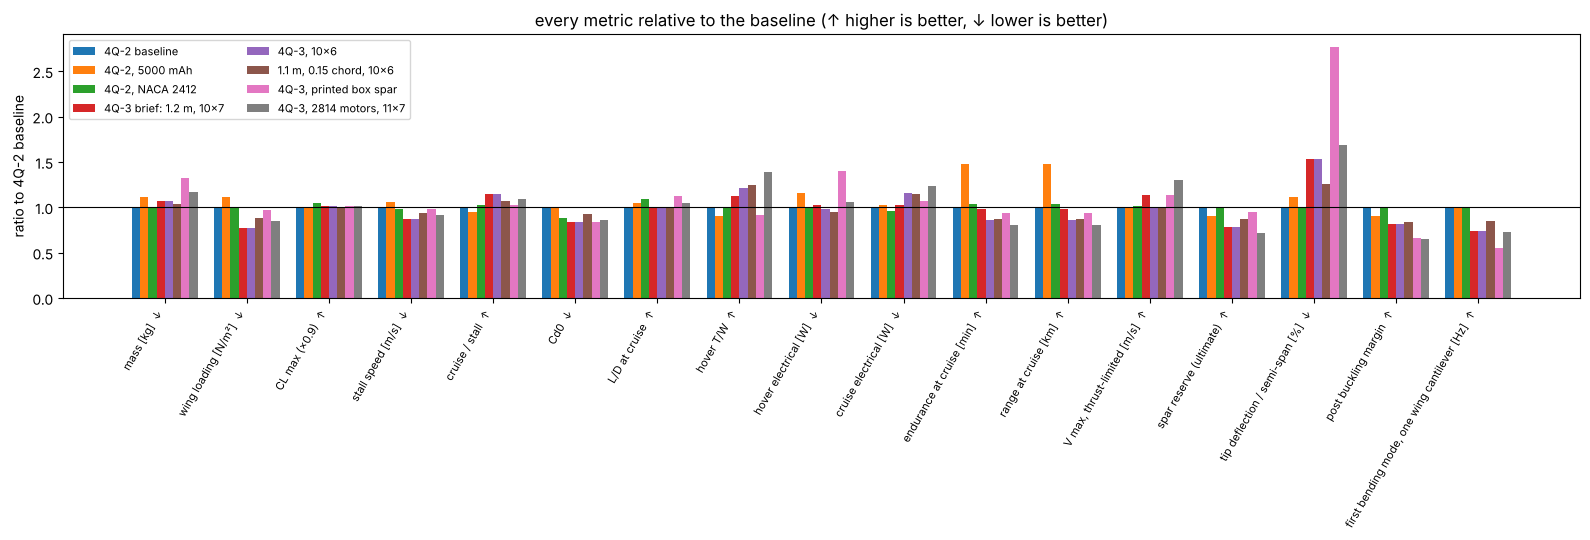

In [3]:
DF = kfa.compare(CANDS)
display(DF[kfa.KEY_COLUMNS].T.round(3))
display(DF[kfa.INTERFERENCE_COLUMNS].T.round(3).rename_axis("wing interference [lattice + Prandtl]: 1.0 = the wings do not feel each other"))
display(DF[["layout rules broken", "section", "section confidence", "Re (chord, cruise)", "hover current per motor [A]", "static thrust per rotor [N]", "pitch speed [m/s]",
            "spar stress, ultimate [MPa]", "spar allowable [MPa]", "spar mass, both wings [kg]", "post Euler load [N]"] + [c for c in DF.columns if c.startswith("plane frame")]].T.round(3))
BASE = CANDS[0].name
fig, ax = plt.subplots(figsize=(16, 5.5)); kfa.plot_ratios(DF, BASE, ax=ax); plt.tight_layout(); plt.show()

## 2b. Biplane against monoplane — and the other machines at this size

The *lift interference factor* above (the pair's lift slope per area over one wing's, lattice) and Prandtl's σ are the
measure of what the two wings take from each other; both move with gap/span, which is why the gap is a candidate
parameter. Below, the first candidate three ways — the biplane, the same span and area as one wing (chord 2c), the
same span and chord as one wing — and the other Vegeta machines (FALCO, NISUS+, MERLIN, PEREGRINE: each design's wing
loading, aspect ratio, Cd0, e and CL max from its design file) rebuilt at this candidate's mass and flown at 16 m/s
with one propulsive efficiency. Analytic, seconds; the CFD chapter K12 measures the three planforms with RANS
(`wf K12`, read in notebook 43).

In [ ]:
import kestrel_compare as kcm
import kestrel_flight as kf
INT = kf.interference(CANDS[0].params())
display(pd.Series(INT["design"], name=f"{CANDS[0].name}: wing interference [lattice + Prandtl]").round(4).to_frame())
display(INT["equivalents"].round(4))
CMP = kcm.compare(CANDS[0].params())
display(CMP.drop(columns=["type", "note"]).astype(float).round(3).T.rename_axis(f"scaled to {CANDS[0].name}'s mass at {kf.V_CRUISE:g} m/s"))
print("\n".join(kcm.verdict(CMP)))

## 3. Targets

The study's targets as ✔ / ✘ per candidate: mass ≤ 2 kg, hover T/W ≥ 2, static margin 0.05–0.15 c, cruise ≥ 1.3 × stall,
endurance ≥ 30 min, spar reserve ≥ 1.5 at ultimate, post buckling margin ≥ 2, tip deflection ≤ 5 % of the semi-span,
hover current ≤ 20 A per motor, no layout rule broken.

In [4]:
V = kfa.verdicts(DF)
display(V)
best = V["targets met"].astype(int).sort_values(ascending=False)
print("ranking by targets met:", ", ".join(f"{n} ({k})" for n, k in best.items()))
print(f"runtime {time.time() - t0:.0f} s for {len(CANDS)} candidates (NeuralFoil polars cached per section and Reynolds number)")

,mass [kg],hover T/W,static margin [chords],cruise / stall,endurance at cruise [min],spar reserve (ultimate),post buckling margin,tip deflection / semi-span [%],hover current per motor [A],layout rules broken,targets met
4Q-2 baseline,✔,✔,✔,✔,✔,✔,✔,✔,✔,✔,10
"4Q-2, 5000 mAh",✔,✔,✔,✔,✔,✔,✔,✔,✔,✔,10
"4Q-2, NACA 2412",✔,✔,✔,✔,✔,✔,✔,✔,✔,✔,10
"4Q-3 brief: 1.2 m, 10x7",✔,✔,✔,✔,✔,✔,✔,✔,✔,✔,10
"4Q-3, 10x6",✔,✔,✔,✔,✘,✔,✔,✔,✔,✔,9
"1.1 m, 0.15 chord, 10x6",✔,✔,✔,✔,✘,✔,✔,✔,✔,✔,9
"4Q-3, printed box spar",✘,✔,✔,✔,✔,✔,✔,✘,✔,✔,8
"4Q-3, 2814 motors, 11x7",✔,✔,✘,✔,✘,✔,✔,✔,✔,✔,8


ranking by targets met: 4Q-2 baseline (10), 4Q-2, 5000 mAh (10), 4Q-2, NACA 2412 (10), 4Q-3 brief: 1.2 m, 10x7 (10), 4Q-3, 10x6 (9), 1.1 m, 0.15 chord, 10x6 (9), 4Q-3, printed box spar (8), 4Q-3, 2814 motors, 11x7 (8)
runtime 92 s for 8 candidates (NeuralFoil polars cached per section and Reynolds number)


## 4. Reading it

- The **stall speed** here is NeuralFoil's $c_{l,max}$ × 0.9 on the wing area; the first CFD campaign read CL max near
  0.53 for the whole airframe (unconverged screening). If the CFD holds, every stall speed above is ~40 % low and the
  wing-area candidates are the ones to keep — that is what the fine `stall` workflow settles (`docs/manual_workflows.md`).
- **Endurance** moves with Cd0 (±20 % in the build-up) and the battery; the 5000 mAh row buys minutes with mass.
- **V max** is the propeller's pitch speed at the motor's full rpm more than it is drag: a 10×7 or an 11×7 is the
  lever, a cleaner airframe is not.
- **Structure**: the printed box spar is feasible at 4 g but heavy and soft (deflection, first mode); a carbon tube
  stays the recommendation of `kestrel3.md`. The posts never buckle. None of this is a strength verdict.
- **Interference**: at gap/chord 2 the lattice's lift interference factor is ~0.9 (a tenth of the lift lost between
  the wings) and the pair's induced drag ~0.7 of the equal-span, equal-area monoplane's; a wider gap buys a few per
  cent of each, a narrower one costs more. Against the conventional monoplanes scaled to this mass the biplane gives
  away L/D for span: that is the trade, not the interference.
- The X-wing and other topologies are not in this comparator (different layout rules); `old/41_xwing` has them.